In [1]:
import numpy as np
import uxarray as ux
from matplotlib import pyplot as plt
from scipy.interpolate import griddata, RegularGridInterpolator
import pygeode as pyg
import os, glob
from jfunctions import *
import scipy.interpolate as intp
from scipy.ndimage import uniform_filter1d
import xarray as xr
from wavenumber_frequency_functions import *


%matplotlib widget

save = False

save_loc = '/home/cwp29/tmp/mpas/'

In [2]:
## data_dir = '/store/ATMOS/cwp29/mpas-a/data/ape_test/120km_2/'
spin_dir = '/data/phh1-hosted/cwp29/mpas-a/120km_update_damping/'
data_dir = '/data/phh1-hosted/cwp29/mpas-a/u_nudge/'
grid_path = '/store/ATMOS/cwp29/mpas-a/grids/x1.40962/x1.40962.grid.nc'

#data_paths = sorted(glob.glob(data_dir+'diag.*.nc'))
#ds = ux.open_mfdataset(grid_path, data_paths, combine="nested", concat_dim="Time")

#dsh = ux.open_dataset(grid_path, run_dir+'latlon_hist.nc')

dsd = pyg.open(data_dir+'latlon_diag.nc')
dsh = pyg.open(data_dir+'latlon_hist.nc')

dsd_spinup = pyg.open(spin_dir+'latlon_diag.nc')
dsh_spinup = pyg.open(spin_dir+'latlon_hist.nc')

In [3]:
def fix_time(var, step=3):
    ''' Replaces loaded 'Time' axis with a PyGeode standard time axixs.'''
    time_axis = pyg.standardtimen('00:00:00 1 Mar 2000', n=len(var.Time), step=step, units='hours')
    return var.replace_axes({'Time': time_axis})

def daily_data(var, n=8):
    ''' Sums every n steps in var.'''
    return np.add.reduceat(var[:], np.arange(0, len(var.time), n))

In [4]:
ndays = 30.
dt = 3. # hours
idx_h = int(ndays * 24./dt)
idx_d = int(ndays)
idx_max_h = len(dsd.Time)
idx_max_d = int(np.ceil(len(dsd.Time)/8))

In [5]:
print(dsh)
print(dsd)

<Dataset>:
Vars:
  qv       (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  qc       (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  qr       (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  qi       (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  qs       (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  qg       (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  zgrid    (nVertLevelsP1,latitude,longitude)     (76,180,360)
  zz       (nVertLevels,latitude,longitude)       (75,180,360)
  pressure (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  rho      (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  theta    (Time,nVertLevels,latitude,longitude)  (528,75,180,360)
  skintemp (Time,latitude,longitude)              (528,180,360)
  sst      (Time,latitude,longitude)              (528,180,360)
Axes:
  Time <NCDim 'Time'>:  0  to 527  (528 values)
  nVertLevels <NCDim 'nVertLevels'>:  0  to 74  (75 values)
  latitude <

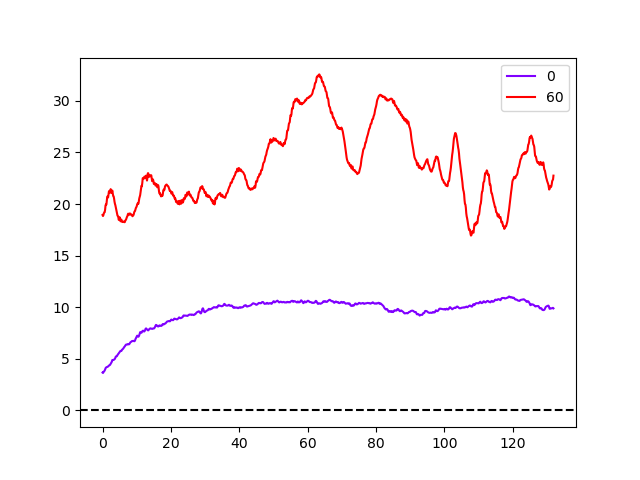

In [6]:
ubar = dsd.uzonal_isobaric.mean('longitude')
pres = np.array([100, 200, 300, 500, 700, 1000, 2000, 3000, 5000, 7000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 70000, 85000, 92500, 100000], dtype=np.float64)
pres /= 100

plt.figure()

lats = [0, 60]
cols = plt.cm.rainbow(np.linspace(0, 1, len(lats)))
for l, c in zip(lats, cols):
    spv = ubar(lat=l, nIsoLevelsU=8)
    plt.plot(np.arange(0, len(dsd.Time[:])/8., 1/8.), spv[:, 0, 0], color=c, label=l)

plt.legend()    
plt.axhline(0, color='k', ls='--')

In [7]:
dTbar = dsd.t_isobaric.diff('Time').mean('longitude', 'Time')[:] / (3/24) # K / day

/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/pygeode/view.py:283: UserWarning: <Var 'dt_isobaric'> is supposed to return a float32, but is returning float64
  warn ("%s is supposed to return a %s, but is returning %s"%(repr(var),var.dtype.name,values.dtype.name))


In [ ]:
lats = dsd.latitude
lons = dsd.longitude

ubar = dsd.uzonal_isobaric.mean('longitude', 'Time')[:]
vbar = dsd.umeridional_isobaric.mean('longitude', 'Time')[:]
omgbar = dsd.omg_isobaric.mean('longitude', 'Time')[:]
rhbar = dsd.rh_isobaric.mean('longitude', 'Time')[:]
Tbar = dsd.t_isobaric.mean('longitude', 'Time')[:]

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True, constrained_layout=True)

pres = np.array([100, 200, 300, 500, 700, 1000, 2000, 3000, 5000, 7000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 70000, 85000, 92500, 100000], dtype=np.float64)
pres /= 100

def plot_Tu_latpres(a, lats, pres, Tbar, ubar, Tlevs=np.arange(190, 305, 5)):
    T_im = a.contourf(lats, pres, Tbar, levels=Tlevs, extend='both', cmap='coolwarm')
    u_im_neg = a.contour(lats, pres, ubar, levels=np.arange(-20, 0, 5), colors='k', linestyles=':', linewidths=0.5)
    u_im_zero = a.contour(lats, pres, ubar, levels=[0], colors='k', linewidths=1)
    u_im_pos = a.contour(lats, pres, ubar, levels=np.arange(5, 55, 5), colors='k', linewidths=0.5)
    a.clabel(u_im_pos, u_im_pos.levels, fontsize=6)
    a.clabel(u_im_neg, u_im_neg.levels, fontsize=6)

    return T_im, u_im_neg, u_im_zero, u_im_pos

def plot_rhv_latpres(a, lats, pres, rhbar, vbar, omgbar):
    xi = np.linspace(lats.min(), lats.max(), len(lats))
    yi = np.linspace(pres.min(), pres.max(), len(pres))

    X, Y = np.meshgrid(xi, yi)

    U = intp.interpn((lats, pres), vbar.T, (X, Y))
    V = intp.interpn((lats, pres), omgbar.T, (X, Y))

    rh_im = a.contourf(lats, pres, rhbar, levels=np.arange(0, 105, 5), cmap='BrBG')
    medcirc_im = a.streamplot(X, Y, U/111111., V/100., color='k', linewidth=1, density=1)

    return rh_im, medcirc_im

T_im, _, _, _ = plot_Tu_latpres(ax[0], lats, pres, Tbar, ubar)
rh_im, _ = plot_rhv_latpres(ax[1], lats, pres, rhbar, vbar, omgbar)
dT_im, _, _, _ = plot_Tu_latpres(ax[2], lats, pres, dTbar, ubar, Tlevs=np.linspace(-0.1, 0.1, 11))

for i in [0, 2]:
    ax[i].invert_yaxis()
    ax[i].set_yscale('log')
    
for a in ax.ravel():
    a.set_xlim(-90, 90)
    a.set_ylim(1000, 10)
    
fig.colorbar(T_im, ax=ax[0], location='bottom', label="temperature (K)")
fig.colorbar(rh_im, ax=ax[1], location='bottom', label="relative humidity (%)")
fig.colorbar(dT_im, ax=ax[2], location='bottom', label=r"temperature tendency (K day$^{-1}$)")

if save: save_fig(fig, save_loc+'comp_temp_relhum.png', dpi=300)

In [ ]:
# Calculate TEM velocities
ds_tem = pyg.open(data_dir+'tem.nc')
print(ds_tem)

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8), sharey=True, constrained_layout=True)

ax[0, 0].set_title(r"$\bar{w}^*$")
ax[1, 0].set_title(r"$\bar{w}$")

ax[0, 1].set_title(r"$\bar{v}^*$")
ax[1, 1].set_title(r"$\bar{v}$")


w_im = ax[0, 0].contourf(lats, pres, ds_tem.wres.mean('Time')[:], levels=np.linspace(-2e-3, 2e-3, 5), cmap='coolwarm', extend='both')
w0_im = ax[1, 0].contourf(lats, pres, ds_tem.w.mean('Time')[:], levels=np.linspace(-2e-3, 2e-3, 5), cmap='coolwarm', extend='both')

v_im = ax[0, 1].contourf(lats, pres, ds_tem.vres.mean('Time')[:], levels=np.linspace(-1, 1, 5), cmap='coolwarm', extend='both')
v0_im = ax[1, 1].contourf(lats, pres, ds_tem.v.mean('Time')[:], levels=np.linspace(-1, 1, 5), cmap='coolwarm', extend='both')

for a in ax.ravel():
    a.invert_yaxis()
    a.set_yscale('log')
    
for a in ax.ravel():
    a.set_xlim(-90, 90)
    a.set_ylim(1000, 10)
    
fig.colorbar(w_im, ax=ax[1, 0], location='bottom')
fig.colorbar(v_im, ax=ax[1, 1], location='bottom')

#if save: save_fig(fig, save_loc+'comp_temp_relhum.png', dpi=300)

In [ ]:
# Calculate TEM velocities
R     = 8.31447215               # J/(mol K), universal gas constant (Wikipedia)
cp    = 1005.7                   # J/(kg K), specific heat of dry air per mass (AMS Glossary)
g0    = 9.80665                  # m/s**2, for geopotential altitude (else actually y-dependent g(y))
Mair  = 0.0289644                # kg/mol, Molecular mass of dry air
Mh2o  = 0.0180153                # kg/mol, Molecular mass of water
Re    = 6371229.                 # m, Radius of planet earth
T0    = 273.15                   # K, Temperature at 0 deg C, i.e. negative absolute zero in Celsius
Omega = 2*np.pi/((23*60+56)*60+4.1) # 1/s, Earth's rotation rate (using siderial day)
Cp    = cp*Mair                  # J/(mol K), specific heat of dry air per mole
Rd    = R/Mair                   # gas constant for dry air
Rw    = R/Mh2o                   # gas constant for water vapour
kappa = R/Cp                     # ~7/2, adiabatic exponent for dry air

p0    = 1000.                  # (hPa) reference surface pressure for, e.g., log pressure heights
H     = 7e3

pres = pyg.Pres(np.array([100, 200, 300, 500, 700, 1000, 2000, 3000, 5000, 7000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 70000, 85000, 92500, 100000])/100.)
lat = dsd.latitude

zs = pres.logPAxis(H=H, p0=p0)
zs = (1.*zs).replace_axes(lev=pres)
phi = lat / 180. * np.pi
dens = 100. * pres / (H * g0)

print(pres)
print(zs[:])
print(dens[:])

In [ ]:
# Calculate eddy fluxes

ua = dsd.uzonal_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h))[:] - ubar[np.newaxis, :, :, np.newaxis]
va = dsd.umeridional_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h))[:] - vbar[np.newaxis, :, :, np.newaxis]
wa = dsd.omg_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h))[:] - omgbar[np.newaxis, :, :, np.newaxis]
Ta = dsd.t_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h))[:] - Tbar[np.newaxis, :, :, np.newaxis]

eke = np.mean(ua*ua + va*va, axis=(0, 3))

vehf = np.mean(wa*Ta, axis=(0, 3))
vemf = np.mean(wa*ua, axis=(0, 3))

mehf = np.mean(va*Ta, axis=(0, 3))
memf = np.mean(va*ua, axis=(0, 3))

In [ ]:
from matplotlib import colors

fig, ax = plt.subplots(5, 1, figsize=(8, 12), constrained_layout='True')

for i, var in enumerate([eke, vemf, vehf, memf, mehf]):
    if i > 2:
        vlim = 5*np.ceil(0.7/5*np.max((np.abs(np.min(var)), np.abs(np.max(var)))))
    else:
        vlim = .1*np.ceil(0.7/.1*np.max((np.abs(np.min(var)), np.abs(np.max(var)))))
    
    if i == 0:
        im = ax[i].contourf(lats, pres, var, cmap='viridis')
    else:
        im = ax[i].contourf(lats, pres, var, cmap='coolwarm', extend='both', levels=np.linspace(-vlim, vlim, 9))
        
    fig.colorbar(im, ax=ax[i], location='right')

for a in ax.ravel():
    a.set_xlim(-90, 90)
    a.invert_yaxis()
    a.set_yscale('log')

ax[0].set_title("Eddy kinetic \n energy (m$^2$ s$^{-2}$)")
ax[1].set_title("Vertical eddy \n momentum flux (m$^2$ s$^{-2}$)")
ax[2].set_title("Vertical eddy \n heat flux (K m s$^{-1}$)")
ax[3].set_title("Meridional eddy \n momentum flux (m$^2$ s$^{-2}$)")
ax[4].set_title("Meridional eddy \n heat flux (K m s$^{-1}$)")

In [ ]:
def lat_pres_plot(var, ax=None, levels=None, cmap='viridis'):
    if ax is None:
        fig = plt.figure()
        if levels is not None:
            plt.contourf(lats, pres, var, cmap=cmap, levels=levels)
        else:
            plt.contourf(lats, pres, var, cmap=cmap)
        
    else:
        if levels is not None:
            ax.contourf(lats, pres, var, cmap=cmap, levels=levels)
        else:
            ax.contourf(lats, pres, var, cmap=cmap)
        return ax

In [ ]:
cldfrac = dsd.cldfrac.mean('Time', 'longitude')[:]

In [ ]:
ilev_dt = dsd.iLev_DT.mean('Time')[:]
print(ilev_dt.shape)

plt.figure()
plt.contourf(lons, lats, ilev_dt)

In [ ]:
zs = dsh.zgrid[:, 0, 0]
print(dsh.zgrid)
print(zs.shape)
print(zs)
print(cldfrac.shape)

plt.figure()
plt.contourf(lats, 0.5*(zs[1:] + zs[:-1]), cldfrac, cmap='binary')